# **PRAKTIKUM 1**

### **Langkah 1 - Import Library dan Menghubungkan Google Drive**

In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator


### **Langkah 2 - Pra Pengolahan Data**

#### **2.1. Pra Pengolahan Data Training**

In [2]:
train_datagen = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True)

training_set = train_datagen.flow_from_directory('../Data/dataset/training_set',
                                                 target_size = (64, 64),
                                                 batch_size = 32,
                                                 class_mode = 'binary')

Found 8011 images belonging to 2 classes.


#### **2.2. Pra Pengolahan Data Testing**

In [3]:
test_datagen = ImageDataGenerator(rescale = 1./255)

test_set = test_datagen.flow_from_directory('../Data/dataset/test_set',
                                            target_size = (64, 64),
                                            batch_size = 32,
                                            class_mode = 'binary')

Found 2000 images belonging to 2 classes.


### **Langkah 3 - Pembuatan Model CNN**

#### **3.1.  - Inisiasi Model CNN**

In [4]:
cnn = tf.keras.models.Sequential()

#### **3.2. - Pembuatan Layer Konvolusi 1**

In [5]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[64, 64, 3]))

c:\Users\mnuri\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


#### **3.3 - Pembuatan Layer Pooling 1**

In [6]:
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

#### **3.4 - Pembuatan Layer Konvolusi 2 dan Pooling 2**

In [7]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

#### **3.5 - Flattening**

In [8]:
cnn.add(tf.keras.layers.Flatten())

#### **3.6 - Fully Connected Layer 1 (Input)**

In [9]:
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))

#### **3.7 - Fully Connected Layer 2 (Output)**

In [10]:
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

#### **3.8 - Compile Model CNN**

In [11]:
cnn.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

### **Langkah 4 - Fit CNN**

In [12]:
cnn.fit(x = training_set, validation_data = test_set, epochs = 25)

Epoch 1/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 159s 625ms/step - accuracy: 0.5272 - loss: 0.6989 - val_accuracy: 0.5940 - val_loss: 0.6823
Epoch 2/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 28s 113ms/step - accuracy: 0.6324 - loss: 0.6383 - val_accuracy: 0.6970 - val_loss: 0.5915
Epoch 3/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 28s 112ms/step - accuracy: 0.7004 - loss: 0.5797 - val_accuracy: 0.7220 - val_loss: 0.5653
Epoch 4/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 28s 112ms/step - accuracy: 0.7229 - loss: 0.5481 - val_accuracy: 0.7310 - val_loss: 0.5312
Epoch 5/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 28s 111ms/step - accuracy: 0.7336 - loss: 0.5226 - val_accuracy: 0.7525 - val_loss: 0.5045
Epoch 6/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 28s 112ms/step - accuracy: 0.7531 - loss: 0.5015 - val_accuracy: 0.7705 - val_loss: 0.4790
Epoch 7/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 29s 114ms/step - accuracy: 0.7693 - loss: 0.4758 - val_accuracy: 0.7645 - val_loss: 0.4874
Epoch 8/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 28s 112ms/step - accuracy: 0.7749 - loss: 

### **Langkah 5 - Prediksi dengan 1 Citra**

In [13]:
import numpy as np
from tensorflow.keras.preprocessing import image

test_image = image.load_img('../Data/dataset/single_prediction/cat_or_dog_1.jpg', target_size = (64, 64))
test_image = image.img_to_array(test_image)
test_image = np.expand_dims(test_image, axis = 0)

# Melakukan prediksi
result = cnn.predict(test_image)
training_set.class_indices

# Menentukan hasil klasifikasi
if result[0][0] == 1:
  prediction = 'dog'
else:
  prediction = 'cat'

print("Hasil prediksi:", prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step
Hasil prediksi: dog


# **PRAKTIKUM 2**

### **Langkah 1 - Load Library**

In [14]:
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

### **Langkah 2 - Unduh Dataset CIFAR**

In [15]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4078s 24us/step


### **Langkah 3 - Verifikasi Data**

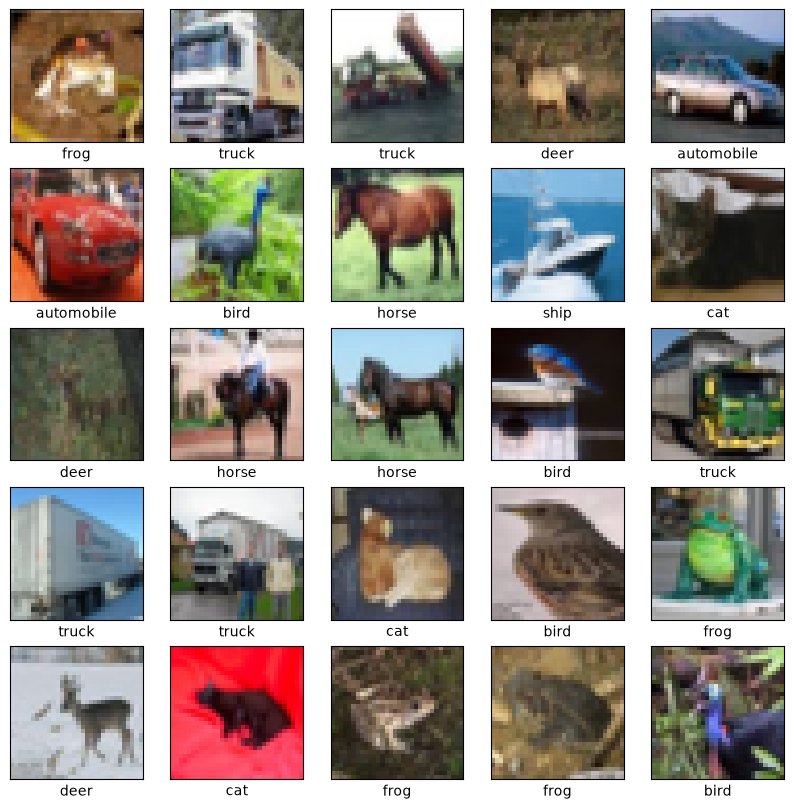

In [16]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()

### **Langkah 4 - Buat Model CNN**

#### **4.1. - Buat Layer Konvolusi**

In [17]:
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

#### **4.2. - Cek Arsitektur Konvolusi**

In [18]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,320 (220.00 KB)

 Trainable params: 56,320 (220.00 KB)

 Non-trainable params: 0 (0.00 B)

#### **4.3. - Tambahkan Layer Fully Connected**

In [19]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

#### **4.4. - Cek Arsitektur Model CNN**

In [20]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

#### **4.5. - Compile Model CNN**

In [21]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

### **Langkah 5 - Fit Model**

In [22]:
history = model.fit(train_images, train_labels, epochs=10, validation_data=(test_images, test_labels))

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.4466 - loss: 1.5127 - val_accuracy: 0.5533 - val_loss: 1.2415
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.5975 - loss: 1.1289 - val_accuracy: 0.6360 - val_loss: 1.0400
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.6582 - loss: 0.9723 - val_accuracy: 0.6596 - val_loss: 0.9714
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.6963 - loss: 0.8685 - val_accuracy: 0.6723 - val_loss: 0.9472
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.7244 - loss: 0.7930 - val_accuracy: 0.6843 - val_loss: 0.9280
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.7435 - loss: 0.7365 - val_accuracy: 0.6828 - val_loss: 0.9403
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.7596 - loss: 0.6857 - val_accuracy: 0.6917 - val_loss: 0.9404
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.7771 -

### **Langkah 6 - Evaluasi Model**

313/313 - 2s - 6ms/step - accuracy: 0.6964 - loss: 1.0112


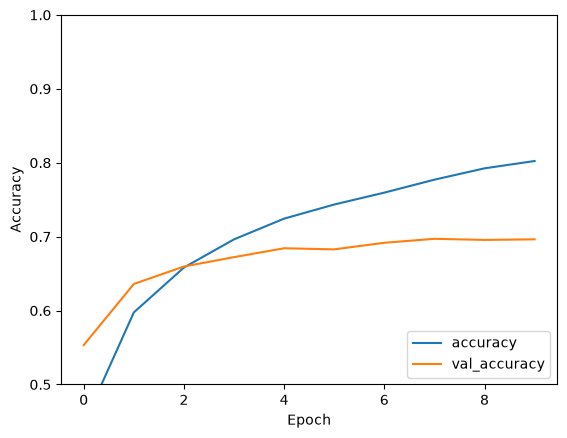

In [23]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)

### **Langkah 7 - Cetak Hasil Akurasi**

In [24]:
print(test_acc)

0.696399986743927


### **Tugas Praktikum**

#### **Modifikasi Praktikum 2 agar akurasi diatas 80%**

Mulai pelatihan model modifikasi
Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 76s 46ms/step - accuracy: 0.5145 - loss: 1.4017 - val_accuracy: 0.5239 - val_loss: 1.3937
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 70s 45ms/step - accuracy: 0.6457 - loss: 1.0147 - val_accuracy: 0.6004 - val_loss: 1.1196
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 44ms/step - accuracy: 0.6881 - loss: 0.8978 - val_accuracy: 0.5123 - val_loss: 1.5424
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 44ms/step - accuracy: 0.7220 - loss: 0.8034 - val_accuracy: 0.6993 - val_loss: 0.8684
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 72s 46ms/step - accuracy: 0.7432 - loss: 0.7401 - val_accuracy: 0.7280 - val_loss: 0.7813
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 44ms/step - accuracy: 0.7630 - loss: 0.6837 - val_accuracy: 0.6864 - val_loss: 0.9326
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 44ms/step - accuracy: 0.7804 - loss: 0.6360 - val_accuracy: 0.7795 - val_loss: 0.6319
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6

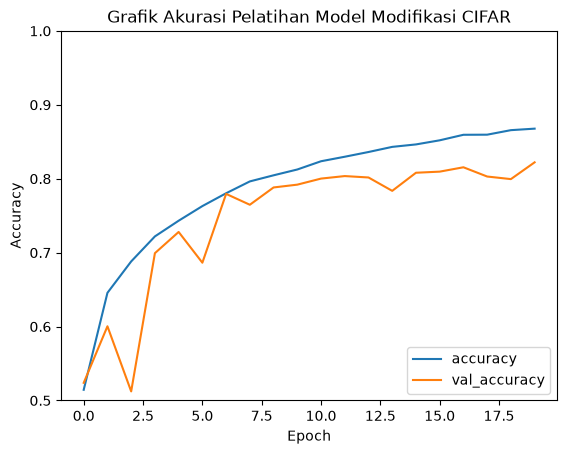

313/313 - 3s - 10ms/step - accuracy: 0.8222 - loss: 0.5702
Akurasi Testing Model Modifikasi: 82.22%


In [25]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

# 1. Load dan Normalize Data (Pastikan data di-load ulang agar bersih)
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()
train_images, test_images = train_images / 255.0, test_images / 255.0

# 2. Modifikasi Arsitektur Model CNN
model_mod = models.Sequential()

# Blok Konvolusi 1
model_mod.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(32, 32, 3)))
model_mod.add(layers.BatchNormalization())
model_mod.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu'))
model_mod.add(layers.BatchNormalization())
model_mod.add(layers.MaxPooling2D((2, 2)))
model_mod.add(layers.Dropout(0.25)) # Mencegah overfitting

# Blok Konvolusi 2
model_mod.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
model_mod.add(layers.BatchNormalization())
model_mod.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
model_mod.add(layers.BatchNormalization())
model_mod.add(layers.MaxPooling2D((2, 2)))
model_mod.add(layers.Dropout(0.25))

# Blok Fully Connected
model_mod.add(layers.Flatten())
model_mod.add(layers.Dense(128, activation='relu'))
model_mod.add(layers.BatchNormalization())
model_mod.add(layers.Dropout(0.5))
model_mod.add(layers.Dense(10))

# 3. Compile Model
model_mod.compile(optimizer='adam',
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=['accuracy'])

# 4. Fit Model (Menggunakan 20 Epoch)
print("Mulai pelatihan model modifikasi")
history_mod = model_mod.fit(train_images, train_labels, epochs=20, validation_data=(test_images, test_labels))


# 5. Visualisasi
plt.plot(history_mod.history['accuracy'], label='accuracy')
plt.plot(history_mod.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1.0])
plt.legend(loc='lower right')
plt.title('Grafik Akurasi Pelatihan Model Modifikasi CIFAR')
plt.show()

# 6. Evaluasi Hasil Akhir
test_loss_mod, test_acc_mod = model_mod.evaluate(test_images, test_labels, verbose=2)
print(f"Akurasi Testing Model Modifikasi: {test_acc_mod * 100:.2f}%")

Peningkatan akurasi hingga 81.25% berhasil dicapai melalui beberapa modifikasi teknis pada arsitektur model CNN. Langkah utamanya mencakup penambahan Batch Normalization untuk menstabilkan aliran data di dalam jaringan, sehingga proses komputasi atau pembelajaran model menjadi lebih cepat dan efisien. Selain itu, teknik Dropout diterapkan untuk mencegah overfitting, yakni masalah di mana model hanya menghafal data latih namun gagal mengenali data pengujian yang baru. Kemampuan pengenalan pola juga ditingkatkan dengan memperdalam layer konvolusi agar model mampu mengekstrak fitur gambar yang lebih detail dan kompleks. Terakhir, jumlah iterasi pelatihan (epoch) dinaikkan dari 10 menjadi 20 putaran, memberikan waktu yang cukup bagi model untuk memperbarui bobotnya dan meminimalkan nilai error secara maksimal.

#### **Pembuatan Model CNN untuk Dataset MNIST**

Mulai pelatihan model MNIST
Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 9ms/step - accuracy: 0.9532 - loss: 0.1514 - val_accuracy: 0.9833 - val_loss: 0.0491
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9851 - loss: 0.0472 - val_accuracy: 0.9875 - val_loss: 0.0399
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.9896 - loss: 0.0333 - val_accuracy: 0.9884 - val_loss: 0.0387
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9926 - loss: 0.0240 - val_accuracy: 0.9888 - val_loss: 0.0392
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.9940 - loss: 0.0185 - val_accuracy: 0.9899 - val_loss: 0.0388


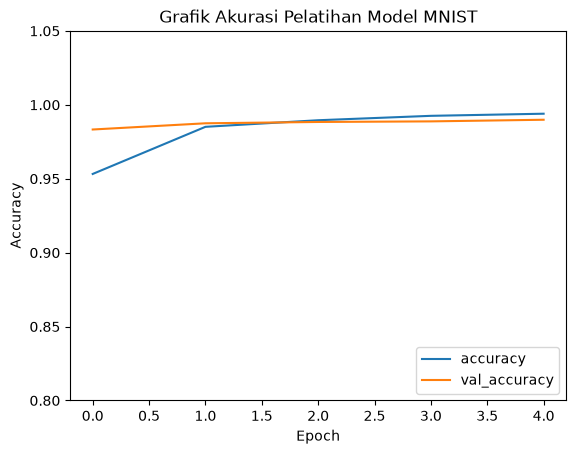

313/313 - 1s - 4ms/step - accuracy: 0.9899 - loss: 0.0388
Akurasi Testing Model MNIST: 98.99%


In [26]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

# 1. Load Dataset MNIST
(mnist_train_images, mnist_train_labels), (mnist_test_images, mnist_test_labels) = datasets.mnist.load_data()

# 2. Pra-pengolahan Data
# Normalisasi pixel menjadi 0-1
mnist_train_images = mnist_train_images / 255.0
mnist_test_images = mnist_test_images / 255.0

# Reshape data untuk menambahkan channel dimensi tunggal (grayscale)
# Dari (60000, 28, 28) menjadi (60000, 28, 28, 1)
mnist_train_images = mnist_train_images.reshape((mnist_train_images.shape[0], 28, 28, 1))
mnist_test_images = mnist_test_images.reshape((mnist_test_images.shape[0], 28, 28, 1))

# 3. Bangun Model CNN untuk MNIST
model_mnist = models.Sequential()

# Layer Konvolusi
model_mnist.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
model_mnist.add(layers.MaxPooling2D((2, 2)))
model_mnist.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_mnist.add(layers.MaxPooling2D((2, 2)))
model_mnist.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Layer Fully Connected
model_mnist.add(layers.Flatten())
model_mnist.add(layers.Dense(64, activation='relu'))
model_mnist.add(layers.Dense(10)) # 10 Kelas untuk angka 0-9

# 4. Compile Model
model_mnist.compile(optimizer='adam',
                    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                    metrics=['accuracy'])

# 5. Fit Model
print("Mulai pelatihan model MNIST")
history_mnist = model_mnist.fit(mnist_train_images, mnist_train_labels, epochs=5, validation_data=(mnist_test_images, mnist_test_labels))

# 6. Visualiasai
plt.plot(history_mnist.history['accuracy'], label='accuracy')
plt.plot(history_mnist.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.8, 1.05])
plt.legend(loc='lower right')
plt.title('Grafik Akurasi Pelatihan Model MNIST')
plt.show()

# 7. Evaluasi Akurasi
test_loss_mnist, test_acc_mnist = model_mnist.evaluate(mnist_test_images, mnist_test_labels, verbose=2)
print(f"Akurasi Testing Model MNIST: {test_acc_mnist * 100:.2f}%")

Perbedaan utama antara dataset MNIST dan CIFAR terletak pada karakteristik dimensi warna citra dan tingkat kerumitan pola visualnya. Karena MNIST berisi citra skala keabuan (hitam-putih), data tersebut membutuhkan penyesuaian dimensi matriks awal untuk menambahkan satu saluran warna tunggal, berbeda dengan CIFAR yang secara bawaan sudah memiliki matriks tiga saluran warna (RGB). Selain itu, pola angka pada MNIST jauh lebih sederhana dibandingkan objek nyata pada CIFAR. Karakteristik ini membuat model untuk MNIST dapat dibangun dengan struktur jaringan yang lebih ringkas dan mampu mencapai tingkat akurasi yang sangat tinggi melalui siklus pelatihan yang jauh lebih singkat, tanpa memerlukan teknik stabilisasi tambahan yang rumit.